In [1]:
import os
import IPython

from transformers import TrainingArguments
print(TrainingArguments.__module__)

import pandas as pd
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch
from datasets import Dataset

import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import numpy as np

transformers.training_args


In [2]:
df = pd.read_csv('5_INPUT_preprocessed_relevant_user_comments.csv')
print(len(df))
df.head()

8699


,comment,replies,date,user_name,source_file,link,manual_label,relevansi,clean_text
0,Prediksi Menteri Keuangan Sri Mulyani Indrawat...,"['Tidak butuh prediksi. Tapi solusi', 'Tdk usa...",2025-04-04T07:16:51Z,@kontantv,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,netral,relevan,prediksi menteri uang sri mulyani indrawati se...
1,korupsi dan pajak yg tinggi lebih berbahaya dr...,[],2025-04-29T10:38:49Z,@victorferry5496,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korupsi pajak bahaya dr tarrif trumph korupsi ...
2,Korups yg di indonesia yg.bikom.parah makanya ...,[],2025-04-29T02:33:56Z,@zannariabintang4812,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korups indonesia ygbikomparah prabowo hukum ko...
3,Maap buk di putus aja hububgan jikala tk teken...,[],2025-04-28T13:11:38Z,@fahmiidris4355,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,maap buk putus hububgan jikala tk teken gitu k...
4,Waduh🫠,[],2025-04-27T02:29:54Z,@PolitikaHistoria,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,NaN


In [3]:
# create copy of df for indobert, mbert, and bert base
df_ib = df.copy()
df_mb = df.copy()
df_bb = df.copy()

# indoBERT

## set encoder

In [8]:
# --- Encode Labels ---
label_encoder = LabelEncoder()
df_ib['labels'] = label_encoder.fit_transform(df_ib['manual_label'])  # Encode labels
print(label_encoder.classes_)

['negatif' 'netral' 'positif']


## train data

In [18]:
# --- Split Data ---
X_train, X_test, y_train, y_test = train_test_split(
    df_ib['clean_text'],
    df_ib['labels'],  # Use encoded labels
    test_size=0.2,
    random_state=42
)

# Over sampling pada data training
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train.values.reshape(-1, 1), y_train)
X_train_resampled = X_train_resampled.flatten()  # Kembalikan ke array 1D

# --- Convert to Huggingface Dataset ---
train_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_train_resampled, 'labels': y_train_resampled}))
test_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_test, 'labels': y_test}))

# --- Load IndoBERT tokenizer dan model ---
tokenizer = BertTokenizer.from_pretrained('indobenchmark/indobert-base-p1')
model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', num_labels=3)

# --- Tokenization ---
def tokenize(batch):
    batch['text'] = [str(t) for t in batch['text']]
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

train_dataset = train_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)
train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
test_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

# --- Training Setup ---
training_args = TrainingArguments(
    output_dir='./results',
    logging_strategy="epoch",  # Log training metrics every epoch.
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_dir='./logs',
    load_best_model_at_end=True,
    save_total_limit=1,
    eval_strategy="epoch",  # Evaluate at the end of each epoch
    save_strategy="epoch",  # Save at the end of each epoch
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# # --- Train Model ---
trainer.train()

# --- Evaluate Model ---
predictions = trainer.predict(test_dataset)
y_pred = predictions.predictions.argmax(-1)
y_true = y_test  # Already encoded

# --- Convert predicted labels back to original labels ---
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Metrics
acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average='macro')
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')

print(f"Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/18510 [00:00<?, ? examples/s]

Map:   0%|          | 0/1740 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,0.215500,0.463145
2,0.035200,0.572257


Accuracy: 0.9322 | F1: 0.6388 | Precision: 0.7421 | Recall: 0.6470


## reporting


indoBERT over sampling Classification Report:
              precision    recall  f1-score   support

     negatif       0.96      0.97      0.96      1499
      netral       0.50      0.07      0.12        57
     positif       0.77      0.90      0.83       184

    accuracy                           0.93      1740
   macro avg       0.74      0.65      0.64      1740
weighted avg       0.92      0.93      0.92      1740



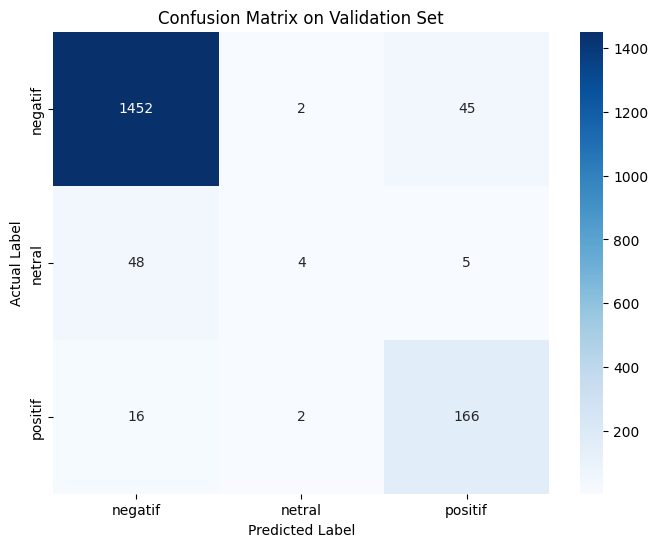

In [19]:
# --- Classification Report ---
print("\nindoBERT over sampling Classification Report:")
print(classification_report(y_true, y_pred, target_names=label_encoder.classes_))

# --- Buat Confusion Matrix validasi ---
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_.tolist(),
            yticklabels=label_encoder.classes_.tolist())
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()


indoBERT over sampling Classification Report:


ValueError: Found input variables with inconsistent numbers of samples: [1740, 8699]

## add predicted_labels to the df

In [11]:
# TODO GANTI NAMA VAR

# --- Tokenization untuk seluruh data ---
def tokenize_all(batch):
    # Gunakan kolom 'clean_text' untuk tokenisasi
    batch['text'] = [str(t) for t in batch['clean_text']]  # Pastikan nama kolomnya sesuai
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

df_dataset = Dataset.from_pandas(df[['clean_text']])  # Ambil hanya kolom clean_text
df_dataset = df_dataset.map(tokenize_all, batched=True)
df_dataset.set_format('torch', columns=['input_ids', 'attention_mask'])

# --- Prediksi pada seluruh dataset ---
predictions = trainer.predict(df_dataset)
y_pred = predictions.predictions.argmax(-1)

# --- Konversi hasil prediksi ke label asli ---
y_pred_labels = label_encoder.inverse_transform(y_pred)

# --- Simpan hasil prediksi ke dalam dataframe ---
df_ib['predicted_labels'] = y_pred_labels

# --- Tampilkan hasil prediksi ---
print(df_ib[['clean_text', 'predicted_labels']].head())

Map:   0%|          | 0/8699 [00:00<?, ? examples/s]

                                          clean_text predicted_labels
0  prediksi menteri uang sri mulyani indrawati se...          negatif
1  korupsi pajak bahaya dr tarrif trumph korupsi ...          negatif
2  korups indonesia ygbikomparah prabowo hukum ko...          negatif
3  maap buk putus hububgan jikala tk teken gitu k...          negatif
4                                                NaN          negatif


In [13]:
len(df_ib)

8699

In [12]:
df_ib.head()

,comment,replies,date,user_name,source_file,link,manual_label,relevansi,clean_text,labels,predicted_labels
0,Prediksi Menteri Keuangan Sri Mulyani Indrawat...,"['Tidak butuh prediksi. Tapi solusi', 'Tdk usa...",2025-04-04T07:16:51Z,@kontantv,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,netral,relevan,prediksi menteri uang sri mulyani indrawati se...,1,negatif
1,korupsi dan pajak yg tinggi lebih berbahaya dr...,[],2025-04-29T10:38:49Z,@victorferry5496,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korupsi pajak bahaya dr tarrif trumph korupsi ...,0,negatif
2,Korups yg di indonesia yg.bikom.parah makanya ...,[],2025-04-29T02:33:56Z,@zannariabintang4812,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korups indonesia ygbikomparah prabowo hukum ko...,0,negatif
3,Maap buk di putus aja hububgan jikala tk teken...,[],2025-04-28T13:11:38Z,@fahmiidris4355,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,maap buk putus hububgan jikala tk teken gitu k...,0,negatif
4,Waduh🫠,[],2025-04-27T02:29:54Z,@PolitikaHistoria,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,NaN,0,negatif


In [14]:
print("predicted negatif", len(df_ib[df_ib['predicted_labels']=='negatif']))
print("predicted netral", len(df_ib[df_ib['predicted_labels']=='netral']))
print("predicted positif", len(df_ib[df_ib['predicted_labels']=='positif']))

print()
print("man label netral", len(df_ib[df_ib['manual_label']=='netral']))
print("predicted positif, tp man label netral", len(df_ib[(df_ib['predicted_labels']=='positif') & (df_ib['manual_label']=='netral')]))
print("predicted negatif, tp man label netral", len(df_ib[(df_ib['predicted_labels']=='negatif') & (df_ib['manual_label']=='netral')]))
print()
print("predicted positif, tp man label negatif", len(df_ib[(df_ib['predicted_labels']=='positif') & (df_ib['manual_label']=='negatif')]))
print("predicted negatif, tp man label positif", len(df_ib[(df_ib['predicted_labels']=='negatif') & (df_ib['manual_label']=='positif')]))

predicted negatif 7553
predicted netral 179
predicted positif 967

man label netral 212
predicted positif, tp man label netral 7
predicted negatif, tp man label netral 46

predicted positif, tp man label negatif 165
predicted negatif, tp man label positif 23


## save file

In [16]:
def save_file(output_file, output_df):
    # Check if the output directory exists, create it if it doesn't
    output_dir = os.path.dirname(output_file)
    if output_dir and not os.path.exists(output_dir):
        try:
            os.makedirs(output_dir)
            print(f"Created directory: {output_dir}")
        except Exception as e:
            print(f"Error creating directory {output_dir}: {e}")
            return False
    
    # Save the dataframe to a new CSV file
    try:
        output_df.to_csv(output_file, index=False)
        print(f"Successfully combined data into {output_file}")
        return True
    except Exception as e:
        print(f"Error writing to output file {output_file}: {e}")

In [17]:
import os
output_file = '5_OUTPUT_with_predicted_labels.csv'
success = save_file(output_file, df_ib)
if success:
    print(f"Combined data saved to {output_file}")
else:
    print("Failed to combine data.")

Successfully combined data into 5_OUTPUT_with_predicted_labels.csv
Combined data saved to 5_OUTPUT_with_predicted_labels.csv
